# Gain fits for my model across sure-emitter thresholds (five 4-fish videos, Kaden masks)

Each setting is one run of `EOD_fish_pair_factors_4fish_kaden*.ipynb` with a different pair of thresholds:
- **distance**: the fish's mask midline is at least `ISO_CM` from every other fish's midline (15, 10, 7 cm);
- **amplitude**: at the pair p* where the fish's prediction is largest, its predicted |v| is at least `DOM` × every other
  fish's (5×, 3×, 2×).

The recording check is the same in every setting (largest recorded |v| at p*, with the predicted sign), and only EODs where
exactly one fish passes are kept.

Fits compared on held-out videos (fit on four videos, median relative residual ‖r − r̂‖/‖r‖ on the fifth, averaged over the
five held-out videos):
- one global gain;
- per-fish only (4);
- per-pair only (10);
- per-fish × per-pair (4 + 10);
- per-fish-per-pair table (40): a separate gain for every fish at every pair.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

BASE, LET = 'results/eod_assign_4fish_kaden', 'ABCD'
OUT = f'{BASE}/fish_pair_factors_threshold_grid'; os.makedirs(OUT, exist_ok=True)
ISOS, DOMS = [15, 10, 7], [5, 3, 2]
def folder(i, d): return f'{BASE}/fish_pair_factors' + ('' if (i, d) == (15, 5) else f'_iso{i}cm_dom{d}')
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
MODEL_COL = {'one global gain': '#8a8a85', 'per-fish only (4)': '#1F5FBF', 'per-pair only (10)': '#F08A24',
             'per-fish × per-pair (4 + 10)': '#C8361E', 'per-fish-per-pair table (40)': '#17A0B0'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b', 'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})

## Sure-emitter EODs per setting

In [2]:
cnt, cv, fac = [], [], []
for i in ISOS:
    for d in DOMS:
        f = folder(i, d)
        S = pd.read_csv(f'{f}/sure_emitter_eods.csv')
        c = S.emitter.value_counts().reindex(list(LET), fill_value=0)
        ct = pd.crosstab(S.emitter, S['pair p* (1-10)']).reindex(index=list(LET), columns=range(1, 11), fill_value=0)
        cnt.append({'distance (cm)': i, 'amplitude (×)': d, 'all': len(S), **{f'fish {k}': c[k] for k in LET},
                    'videos with ≥ 50 EODs of every fish': int((pd.crosstab(S.video, S.emitter).reindex(columns=list(LET), fill_value=0) >= 50).all(1).sum()),
                    'fish-pair cells with ≥ 20 EODs (of 40)': int((ct >= 20).values.sum())})
        V = pd.read_csv(f'{f}/leave_one_video_out.csv'); V['distance (cm)'] = i; V['amplitude (×)'] = d; cv.append(V)
        F = pd.read_csv(f'{f}/fish_pair_factors.csv', index_col=0); F['distance (cm)'] = i; F['amplitude (×)'] = d; fac.append(F)
C = pd.DataFrame(cnt); CV = pd.concat(cv, ignore_index=True); FAC = pd.concat(fac)
C.to_csv(f'{OUT}/sure_emitter_counts.csv', index=False)
display(C.set_index(['distance (cm)', 'amplitude (×)']))

all  fish A  fish B  fish C  fish D  \
distance (cm) amplitude (×)                                          
15            5              23630    5169   13695    1770    2996   
              3              26355    5447   15210    2155    3543   
              2              28782    5676   16773    2372    3961   
10            5              26926    6257   15559    1990    3120   
              3              31580    6939   18246    2649    3746   
              2              35398    7416   20550    3124    4308   
7             5              31448    7496   18422    2323    3207   
              3              39099    8894   22952    3353    3900   
              2              46106   10016   27404    4119    4567   

                             videos with ≥ 50 EODs of every fish  \
distance (cm) amplitude (×)                                        
15            5                                                2   
              3                                                2   
              2                                                4   
10            5                                                3   
              3                                                4   
              2                                                4   
7             5                                                3   
              3                                                4   
              2                                                4   

                             fish-pair cells with ≥ 20 EODs (of 40)  
distance (cm) amplitude (×)                                          
15            5                                                  32  
              3                                                  36  
              2                                                  38  
10            5                                                  34  
              3                                                  37  
              2                                                  39  
7             5                                                  34  
              3                                                  37  
              2                                                  39

## Held-out residual per setting and fit

In [3]:
H = CV.groupby(['distance (cm)', 'amplitude (×)', 'model'], sort=False)['median relative residual'].agg(['mean', 'min', 'max']).reset_index()
H.to_csv(f'{OUT}/held_out_residual_by_setting.csv', index=False)
display(H.pivot_table(index=['distance (cm)', 'amplitude (×)'], columns='model', values='mean', sort=False).round(3))

model                        one global gain  per-fish only (4)  \
distance (cm) amplitude (×)                                       
15            5                        0.383              0.320   
              3                        0.460              0.434   
              2                        0.552              0.529   
10            5                        0.393              0.336   
              3                        0.504              0.465   
              2                        0.589              0.556   
7             5                        0.434              0.387   
              3                        0.564              0.518   
              2                        0.635              0.596   

model                        per-pair only (10)  per-fish × per-pair (4 + 10)  \
distance (cm) amplitude (×)                                                     
15            5                           0.340                         0.326   
              3                           0.496                         0.475   
              2                           0.573                         0.564   
10            5                           0.363                         0.351   
              3                           0.534                         0.501   
              2                           0.609                         0.587   
7             5                           0.419                         0.415   
              3                           0.578                         0.549   
              2                           0.647                         0.627   

model                        per-fish-per-pair table (40)  
distance (cm) amplitude (×)                                
15            5                                     0.310  
              3                                     0.465  
              2                                     0.543  
10            5                                     0.329  
              3                                     0.482  
              2                                     0.559  
7             5                                     0.388  
              3                                     0.537  
              2                                     0.605

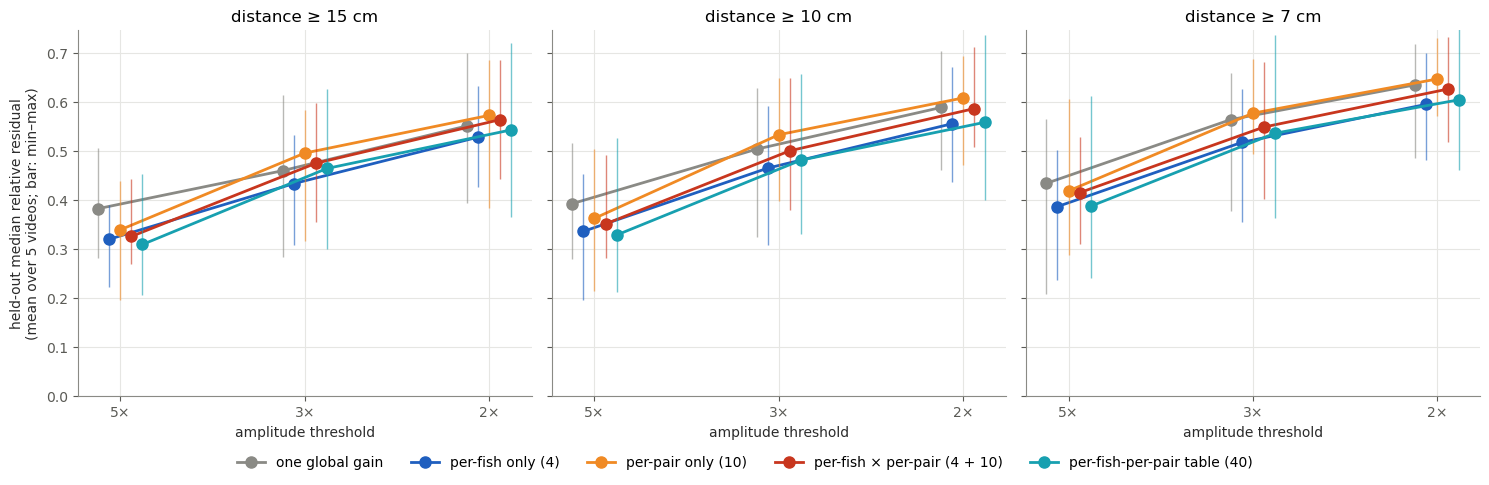

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, i in zip(axs, ISOS):
    for k, (m, col) in enumerate(MODEL_COL.items()):
        h = H[(H['distance (cm)'] == i) & (H.model == m)].set_index('amplitude (×)').reindex(DOMS)
        x = np.arange(len(DOMS)) + (k - 2) * 0.06
        ax.plot(x, h['mean'], '-o', color=col, lw=2, ms=8, label=m)
        ax.vlines(x, h['min'], h['max'], color=col, lw=1, alpha=0.6)
    ax.set(xticks=range(len(DOMS)), xticklabels=[f'{d}×' for d in DOMS], xlabel='amplitude threshold',
           title=f'distance ≥ {i} cm', ylim=(0, None))
axs[0].set_ylabel('held-out median relative residual\n(mean over 5 videos; bar: min–max)')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); fig.savefig(f'{OUT}/held_out_residual_by_setting.png', dpi=120, bbox_inches='tight'); plt.show()

## Same test EODs for every setting

Each setting above is tested on its own sure EODs, and looser thresholds add harder EODs (and some with the wrong emitter),
so those residuals are not comparable between settings. Here every setting is fitted on its own sure EODs of four videos and
tested on the **strict (15 cm, 5×) sure EODs** of the fifth video, so only the training set changes.

In [5]:
def fit(R, M, fi, fish=True, pair=True, weight=True, iters=200):
    w = 1 / np.linalg.norm(R, axis=1, keepdims=True) if weight else np.ones((len(R), 1))
    Rw, Mw = R * w, M * w
    a, b = np.ones(4), np.ones(10)
    for _ in range(iters):
        X = Mw * b
        if fish: a = np.array([(Rw[fi == f] * X[fi == f]).sum() / (X[fi == f] ** 2).sum() if (fi == f).any() else np.nan for f in range(4)])
        else: a = np.full(4, (Rw * X).sum() / (X ** 2).sum())
        if pair:
            Y = Mw * a[fi, None]; b = (Rw * Y).sum(0) / (Y ** 2).sum(0); b = b / np.exp(np.mean(np.log(np.abs(b))))
    return a, b

def fit_table(R, M, fi, weight=True):
    w = 1 / np.linalg.norm(R, axis=1, keepdims=True) if weight else np.ones((len(R), 1))
    Rw, Mw = R * w, M * w
    a, b = fit(R, M, fi, weight=weight); g = a[:, None] * b[None]
    for f in range(4):
        m = fi == f
        if m.any(): g[f] = np.where((Mw[m] ** 2).sum(0) > 0, (Rw[m] * Mw[m]).sum(0) / np.maximum((Mw[m] ** 2).sum(0), 1e-300), g[f])
    return g

PV = {t: np.load(f'{BASE}/{t}/predicted_voltages.npz') for t in pd.read_csv(f'{folder(15, 5)}/sure_emitter_eods.csv').video.unique()}
def arrays(i, d):
    S = pd.read_csv(f'{folder(i, d)}/sure_emitter_eods.csv')
    fi = S.emitter.map({f: k for k, f in enumerate(LET)}).to_numpy()
    R = np.concatenate([PV[t]['recorded_peak'][g.row.to_numpy()] for t, g in S.groupby('video', sort=False)])
    M = np.concatenate([PV[t]['mine_unit_current'][g.row.to_numpy(), fi[g.index]] for t, g in S.groupby('video', sort=False)])
    order = np.concatenate([g.index.to_numpy() for _, g in S.groupby('video', sort=False)])
    return S.video.to_numpy()[order], R, M, fi[order]

vt, Rt, Mt, Ft = arrays(15, 5)                                                 # common test EODs
MODELS = {'one global gain': dict(fish=False, pair=False), 'per-fish only (4)': dict(fish=True, pair=False),
          'per-pair only (10)': dict(fish=False, pair=True), 'per-fish × per-pair (4 + 10)': dict(fish=True, pair=True),
          'per-fish-per-pair table (40)': None}
rows = []
for i in ISOS:
    for d in DOMS:
        v, R, M, fi = arrays(i, d)
        for t in PV:
            tr, te = v != t, vt == t
            for m, kw in MODELS.items():
                if kw is None: G = fit_table(R[tr], M[tr], fi[tr])[Ft[te]]
                else: aa, bb = fit(R[tr], M[tr], fi[tr], **kw); G = aa[Ft[te], None] * bb[None]
                e = np.linalg.norm(Rt[te] - G * Mt[te], axis=1) / np.linalg.norm(Rt[te], axis=1)
                rows.append({'distance (cm)': i, 'amplitude (×)': d, 'held-out video': t, 'model': m, 'median relative residual': np.median(e)})
CT = pd.DataFrame(rows)
HC = CT.groupby(['distance (cm)', 'amplitude (×)', 'model'], sort=False)['median relative residual'].agg(['mean', 'min', 'max']).reset_index()
HC.to_csv(f'{OUT}/held_out_residual_common_test.csv', index=False)
display(HC.pivot_table(index=['distance (cm)', 'amplitude (×)'], columns='model', values='mean', sort=False).round(3))

model                        one global gain  per-fish only (4)  \
distance (cm) amplitude (×)                                       
15            5                        0.383              0.320   
              3                        0.454              0.431   
              2                        0.546              0.523   
10            5                        0.382              0.325   
              3                        0.483              0.452   
              2                        0.566              0.543   
7             5                        0.395              0.360   
              3                        0.520              0.492   
              2                        0.591              0.573   

model                        per-pair only (10)  per-fish × per-pair (4 + 10)  \
distance (cm) amplitude (×)                                                     
15            5                           0.340                         0.326   
              3                           0.485                         0.465   
              2                           0.560                         0.551   
10            5                           0.356                         0.339   
              3                           0.497                         0.469   
              2                           0.575                         0.558   
7             5                           0.378                         0.365   
              3                           0.506                         0.481   
              2                           0.580                         0.562   

model                        per-fish-per-pair table (40)  
distance (cm) amplitude (×)                                
15            5                                     0.310  
              3                                     0.453  
              2                                     0.532  
10            5                                     0.309  
              3                                     0.446  
              2                                     0.528  
7             5                                     0.323  
              3                                     0.458  
              2                                     0.540

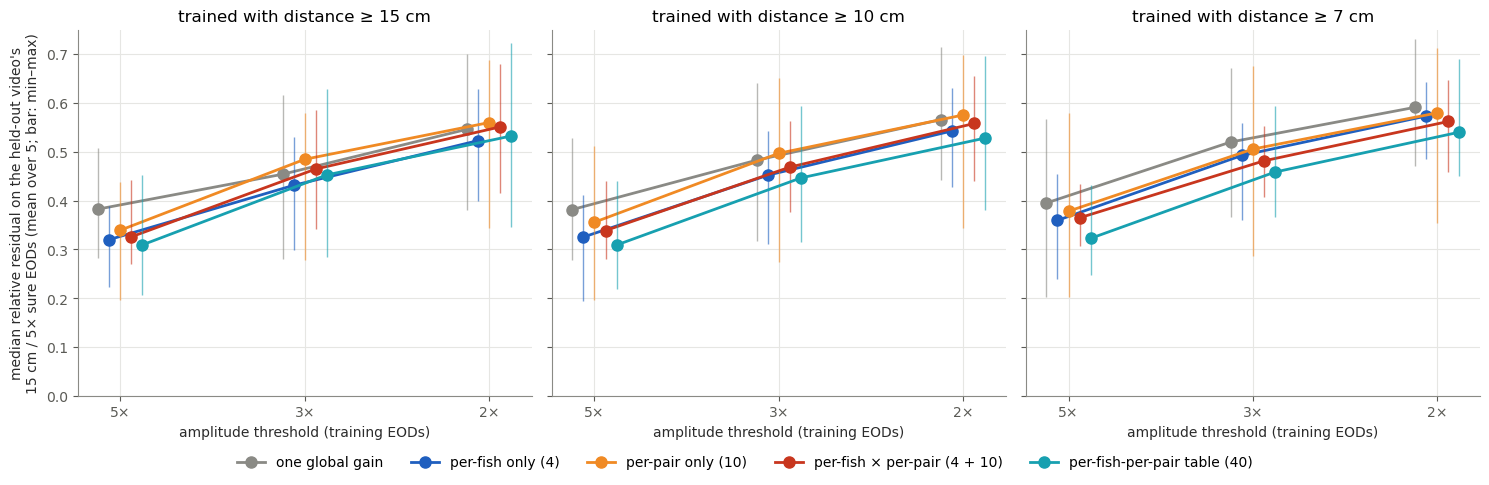

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, i in zip(axs, ISOS):
    for k, (m, col) in enumerate(MODEL_COL.items()):
        h = HC[(HC['distance (cm)'] == i) & (HC.model == m)].set_index('amplitude (×)').reindex(DOMS)
        x = np.arange(len(DOMS)) + (k - 2) * 0.06
        ax.plot(x, h['mean'], '-o', color=col, lw=2, ms=8, label=m)
        ax.vlines(x, h['min'], h['max'], color=col, lw=1, alpha=0.6)
    ax.set(xticks=range(len(DOMS)), xticklabels=[f'{d}×' for d in DOMS], xlabel='amplitude threshold (training EODs)',
           title=f'trained with distance ≥ {i} cm', ylim=(0, None))
axs[0].set_ylabel('median relative residual on the held-out video\'s\n15 cm / 5× sure EODs (mean over 5; bar: min–max)')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); fig.savefig(f'{OUT}/held_out_residual_common_test.png', dpi=120, bbox_inches='tight'); plt.show()

## Per-fish factors (per-fish × per-pair fit on all five videos) per setting

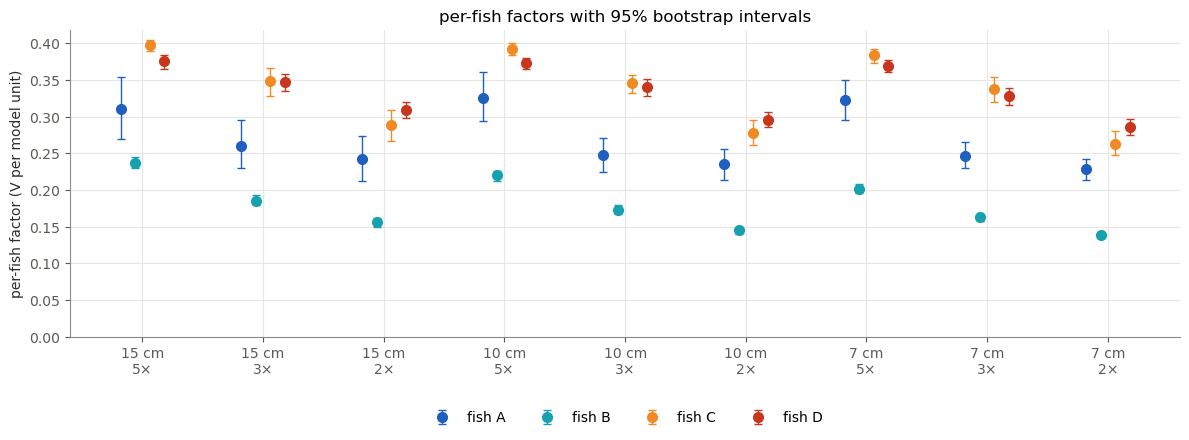

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.6))
labels = [f'{i} cm\n{d}×' for i in ISOS for d in DOMS]
for j, f in enumerate(LET):
    r = FAC.loc[f'fish {f}']
    x = np.arange(len(r)) + (j - 1.5) * 0.12
    ax.errorbar(x, r['factor'], yerr=[r['factor'] - r['95% low'], r['95% high'] - r['factor']], fmt='o', ms=7, color=FISH_COL[f],
                capsize=3, lw=1, label=f'fish {f}')
ax.set(xticks=range(len(labels)), xticklabels=labels, ylabel='per-fish factor (V per model unit)', ylim=(0, None),
       title='per-fish factors with 95% bootstrap intervals')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); fig.savefig(f'{OUT}/fish_factors_by_setting.png', dpi=120, bbox_inches='tight'); plt.show()
FAC.reset_index(names='factor name').to_csv(f'{OUT}/factors_by_setting.csv', index=False)